
![](https://sibcolombia.net/wp-content/uploads/2016/05/Logo-javeriana.png)

**PONTIFICIA UNIVERSIDAD JAVERIANA**

**FECHA** : 29/09/2026

**CLASE : PROCESAMIENTO DE DATOS A GRAN ESCALA**

**AUTOR : SERGIO SAMUEL CLAVIJO LOPEZ**

**TEMA : PySpark con modelos de Machine Learning de derrames cerebrales**

**OBJETIVOS :**
- Aplicar la metodologia de CRISP DM en datasets de ciencias de la salud
- Documentar cada actividad realizada
- Crear, comprender y analizar las graficas generadas
- Hacer analisis y conclusiones correspondientes


In [65]:
#Generic Libraries
import numpy as np                                                      # linear algebra
import pandas as pd                                                     # data processing, CSV file I/O (e.g. pd.read_csv)
import seaborn as sns                                                   # Creacion de graficas y biblioteca estadistica
import matplotlib.pyplot as plt                                         # Implementacion de grafica

#Apache Spark libreries
import findspark
findspark.init('/mnt/sda1/Cluster/Spark/')


##Bibliotecas para configuraciones y SESION SPARK
import pyspark
from pyspark import SparkConf, SparkContext                           #SparkConf:            ||SparkContext
from pyspark.sql import SparkSession, SQLContext
from pyspark.sql import functions as F

#Apache Spark ML CLassifier Libraries
from pyspark.ml.classification import DecisionTreeClassifier,RandomForestClassifier,NaiveBayes

#Apache Spark Evaluation Library
from pyspark.ml.evaluation import MulticlassClassificationEvaluator

#Apache Spark Features libraries
from pyspark.ml.feature import StandardScaler,StringIndexer, VectorAssembler, VectorIndexer, OneHotEncoder

#Apache Spark Pipelin Library
from pyspark.ml import Pipeline

# Apache Spark `DenseVector`
from pyspark.ml.linalg import DenseVector

#Data Split Libraries
import sklearn
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix

In [4]:
## Se crea una configuracion para la sesion SPARK

#Se configura
configura = SparkConf().set("spark.ui.port","37006")
configura.setAppName("DerrameSparkBigData_Clavijo03")
#Se crea contexto para la sesion
sparkClavijo = SparkSession.builder.config(conf=configura).getOrCreate()
SQLContext(sparkContext=sparkClavijo.sparkContext, sparkSession=sparkClavijo)

#Se levanta el contexto para la sesion: Aplkicacion de derrame cerebral en SPARK
sparkContextClavijo = sparkClavijo.sparkContext.getOrCreate()

#Se imprime para verificarfrom pyspark.sql import function as F                                   #Se importa todas las funciones: when, column, .....
from pyspark.sql.types import *
print("Sesion creada el 17 de noviembre del 2026")
sparkClavijo


Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).


Sesion creada el 17 de noviembre del 2026


### **Acceso al DATA LAKE Hadoop HDFS**
#COMENTAR

In [5]:
## Revisar los archivos disponibles o datasets
!/mnt/sda1/Cluster/Hadoop/bin/hadoop fs -ls /

Found 13 items
drwxr-xr-x   - sistemas  supergroup          0 2025-10-31 15:50 /DistriFlipa
drwxrwxrwx   - sistemas  supergroup          0 2026-10-30 08:30 /FAC_Dataset
drwxrwxrwx   - sistemas  supergroup          0 2026-11-18 07:23 /Formatos1055
drwxrwxrwx   - sistemas  supergroup          0 2026-11-17 07:26 /Formatos1255
drwxrwxrwx   - sistemas  supergroup          0 2026-11-12 18:15 /FormatosHPC
drwxr-xr-x   - seguridad supergroup          0 2026-11-14 23:34 /benchmark
drwxr-xr-x   - sistemas  supergroup          0 2026-11-12 12:15 /csv
drwxr-xr-x   - sistemas  supergroup          0 2026-11-17 15:59 /images
drwxr-xr-x   - sistemas  supergroup          0 2025-09-02 13:23 /json
drwxr-xr-x   - sistemas  supergroup          0 2025-09-02 16:56 /parquet
drwxrwxr-x+  - userpm025 supergroup          0 2025-10-25 17:51 /pm25
drwxrwxrwx   - sistemas  supergroup          0 2026-11-13 16:19 /seguridad
drwxr-xr-x   - usuario22 usuario22           0 2026-04-15 15:19 /user22


In [6]:
## Revisar los archivos datasets carpeta CSV
!/mnt/sda1/Cluster/Hadoop/bin/hadoop fs -ls /csv

Found 11 items
drwxr-xr-x   - sistemas supergroup          0 2026-10-23 13:39 /csv/BankMarketing
-rw-r--r--   2 sistemas supergroup     977501 2026-03-10 15:27 /csv/CustomerChurn.csv
-rw-r--r--   2 sistemas supergroup      40868 2025-07-07 15:41 /csv/Fortune500USCompanies.csv
drwxr-xr-x   - sistemas supergroup          0 2025-10-16 14:17 /csv/auxiliar
drwxr-xr-x   - sistemas supergroup          0 2026-11-12 12:16 /csv/calidadAgua
-rw-r--r--   2 sistemas supergroup      34635 2025-09-02 13:22 /csv/jugadores.csv
-rw-r--r--   2 sistemas supergroup    1082023 2025-09-02 13:22 /csv/resultados_futbol.csv
-rw-r--r--   2 sistemas supergroup     316971 2025-06-10 09:11 /csv/stroke_pyspark.csv
drwxr-xr-x   - sistemas supergroup          0 2025-06-18 15:36 /csv/taxi
drwxr-xr-x   - sistemas supergroup          0 2026-04-23 15:56 /csv/titanic
-rw-r--r--   2 sistemas supergroup      84199 2026-04-23 17:11 /csv/winequality-red.csv


In [7]:
## Revisar archivo en especifico con la ruta (este es un ejemplo)
!/mnt/sda1/Cluster/Hadoop/bin/hadoop fs -ls /csv/taxi

Found 3 items
-rw-r--r--   2 sistemas supergroup      89594 2025-06-18 15:19 /csv/taxi/taxi-etl-input-small.csv
-rw-r--r--   2 sistemas supergroup     278795 2025-06-18 15:26 /csv/taxi/taxi-test.csv
-rw-r--r--   2 sistemas supergroup    1114146 2025-06-18 15:26 /csv/taxi/taxi-train.csv


In [8]:
#Se crea el DATAFRAME SPARK con el fichero dataset en STROKE
url = 'hdfs://10.195.34.34:9000/csv/stroke_pyspark.csv'
#stroke_pysparkPP.csv
df00 = sparkClavijo.read.format("csv") \
       .option("header", "true") \
       .option("inferSchema","true")\
       .load(url) 
df00.show(5)

+-----+------+----+------------+-------------+------------+-------------+--------------+-----------------+----+---------------+------+
|   id|gender| age|hypertension|heart_disease|ever_married|    work_type|Residence_type|avg_glucose_level| bmi| smoking_status|stroke|
+-----+------+----+------------+-------------+------------+-------------+--------------+-----------------+----+---------------+------+
| 9046|  Male|67.0|           0|            1|         Yes|      Private|         Urban|           228.69|36.6|formerly smoked|     1|
|51676|Female|61.0|           0|            0|         Yes|Self-employed|         Rural|           202.21| N/A|   never smoked|     1|
|31112|  Male|80.0|           0|            1|         Yes|      Private|         Rural|           105.92|32.5|   never smoked|     1|
|60182|Female|49.0|           0|            0|         Yes|      Private|         Urban|           171.23|34.4|         smokes|     1|
| 1665|Female|79.0|           1|            0|         

**DIAGNOSTICO Y TRATAMIENTO DE DATOS**
- Cambio de nombres de consultas (features)
- Tipos y coherencia de datos
- Identificacion y tratamiento de datos nulos/atipicos
- Estadistica de los datos
- Tratamiento de columnas categoricas

In [9]:
## Consulto el nombre de las columnas
df00.columns

['id',
 'gender',
 'age',
 'hypertension',
 'heart_disease',
 'ever_married',
 'work_type',
 'Residence_type',
 'avg_glucose_level',
 'bmi',
 'smoking_status',
 'stroke']

In [10]:
nuevosNombre = ['id','Genero','Edad','Hipertension',
                'EnfCardiaco','EdoCivil','TipoTrabajo',
                'TipoResidencia','NivelGlucosa','IMC',
                'Fumador','Derrame']
## Se cambian por los nuevos nombres en un nuevo Dataframe
df01 = df00
for antes, nuevo in zip(df00.columns, nuevosNombre):
    df01 = df01.withColumnRenamed(antes, nuevo)

df01.columns

['id',
 'Genero',
 'Edad',
 'Hipertension',
 'EnfCardiaco',
 'EdoCivil',
 'TipoTrabajo',
 'TipoResidencia',
 'NivelGlucosa',
 'IMC',
 'Fumador',
 'Derrame']

 **JUSTIFICAR LA SALIDA DE LA VARIABLE ID**
- Eliminamos la variable id porque a la hora de empezar a tratar esta base de datos no influye en la calidad de los datos.
- Al generalmente ser un dato que viene en orden cronologico no terminan dando importancia a la hora de empezar nuestro tratamiento
- El id no genera valor agregado en nuestro modelo
- Al ser una columna mas puede hacer mas pesada nuestra tabla


In [11]:
#Tipos de datos de las variables
df01.printSchema()

root
 |-- id: integer (nullable = true)
 |-- Genero: string (nullable = true)
 |-- Edad: double (nullable = true)
 |-- Hipertension: integer (nullable = true)
 |-- EnfCardiaco: integer (nullable = true)
 |-- EdoCivil: string (nullable = true)
 |-- TipoTrabajo: string (nullable = true)
 |-- TipoResidencia: string (nullable = true)
 |-- NivelGlucosa: double (nullable = true)
 |-- IMC: string (nullable = true)
 |-- Fumador: string (nullable = true)
 |-- Derrame: integer (nullable = true)



In [12]:
#Mostrar 4 filas de el dataframe
df01.show(4)

[Stage 3:>                                                          (0 + 1) / 1]

+-----+------+----+------------+-----------+--------+-------------+--------------+------------+----+---------------+-------+
|   id|Genero|Edad|Hipertension|EnfCardiaco|EdoCivil|  TipoTrabajo|TipoResidencia|NivelGlucosa| IMC|        Fumador|Derrame|
+-----+------+----+------------+-----------+--------+-------------+--------------+------------+----+---------------+-------+
| 9046|  Male|67.0|           0|          1|     Yes|      Private|         Urban|      228.69|36.6|formerly smoked|      1|
|51676|Female|61.0|           0|          0|     Yes|Self-employed|         Rural|      202.21| N/A|   never smoked|      1|
|31112|  Male|80.0|           0|          1|     Yes|      Private|         Rural|      105.92|32.5|   never smoked|      1|
|60182|Female|49.0|           0|          0|     Yes|      Private|         Urban|      171.23|34.4|         smokes|      1|
+-----+------+----+------------+-----------+--------+-------------+--------------+------------+----+---------------+-------+


#### **Se castea o pasa al tipo de datos numerico coherente**
- La edad debe ser entera
- Nivel glucosa debe ser double (flotante,numeros decimales)

In [13]:
### Edad: double se cambia a entero
df02 = df01.withColumn("Edad", df01.Edad.cast("int"))
### Hipertension : integer, se castea a entero
df02 = df02.withColumn("Hipertension", df02.Hipertension.cast("int"))
### EnfCardiaco : integer, se castea a entero
df02 = df02.withColumn("EnfCardiaco", df02.EnfCardiaco.cast("int"))
### NivelGlucosa: double, se castea a double
df02 = df02.withColumn("NivelGlucosa", df02.NivelGlucosa.cast("double"))
### IMC : string, se castea a double
df02 = df02.withColumn("IMC", df02.IMC.cast("double"))
### Derrame: integer, se castea a entero
df02 = df02.withColumn("Derrame", df02.Derrame.cast("int"))
df02.printSchema()

root
 |-- id: integer (nullable = true)
 |-- Genero: string (nullable = true)
 |-- Edad: integer (nullable = true)
 |-- Hipertension: integer (nullable = true)
 |-- EnfCardiaco: integer (nullable = true)
 |-- EdoCivil: string (nullable = true)
 |-- TipoTrabajo: string (nullable = true)
 |-- TipoResidencia: string (nullable = true)
 |-- NivelGlucosa: double (nullable = true)
 |-- IMC: double (nullable = true)
 |-- Fumador: string (nullable = true)
 |-- Derrame: integer (nullable = true)



In [14]:
## Se crea una tabla para la identificacion y tratamiento de datos nulos/atipícos
df02.select([F.count(F.when(F.isnan(c) | F.col(c).isNull(), c)).alias(c) for c in df02.columns]).show()

+---+------+----+------------+-----------+--------+-----------+--------------+------------+---+-------+-------+
| id|Genero|Edad|Hipertension|EnfCardiaco|EdoCivil|TipoTrabajo|TipoResidencia|NivelGlucosa|IMC|Fumador|Derrame|
+---+------+----+------------+-----------+--------+-----------+--------------+------------+---+-------+-------+
|  0|     0|   0|           0|          0|       0|          0|             0|           0|201|      0|      0|
+---+------+----+------------+-----------+--------+-----------+--------------+------------+---+-------+-------+



#### Se observa
- Las variables en general no tienen datos nulos, a excepcion de la variable IMC
- Sin embargo se observa que la variable IMC es importante dado que necesitamos una gran precision en todo el analisis

In [15]:
#Muestra las variables de el nuevo DataFrame
df02.columns

['id',
 'Genero',
 'Edad',
 'Hipertension',
 'EnfCardiaco',
 'EdoCivil',
 'TipoTrabajo',
 'TipoResidencia',
 'NivelGlucosa',
 'IMC',
 'Fumador',
 'Derrame']

### Observacion y tratamiento sobre variables de categorias
- Genero
- EdoCivil
- TipoTrabajo
- TipoResidencia
- Fumador

In [16]:
# Cuales generos hay en el dataset
df02.groupby(['Genero']).count().show()

+------+-----+
|Genero|count|
+------+-----+
|Female| 2994|
| Other|    1|
|  Male| 2115|
+------+-----+



- Se puede observar que el genero con mas datos es en femenino
- Existen 3 generos
- Other al ser un dato atipico y en este caso solo ser 1 se eliminaria

In [17]:
#Cuenta los casados
df02.groupby(['EdoCivil']).count().show()

+--------+-----+
|EdoCivil|count|
+--------+-----+
|      No| 1757|
|     Yes| 3353|
+--------+-----+



- Se observa que la mayoria de personas estan casadas
- El dato solo muestra si esta casado o no

In [18]:
#Cuenta el tipo de su trabajo
df02.groupby(['TipoTrabajo']).count().show()

+-------------+-----+
|  TipoTrabajo|count|
+-------------+-----+
| Never_worked|   22|
|Self-employed|  819|
|      Private| 2925|
|     children|  687|
|     Govt_job|  657|
+-------------+-----+



- Existen 5 tipos de trabajo
- Solo 22 personas nunca han trabajado siendo el dato con menor cantidad de personas
- La mayoria trabaja en empresa privada

In [19]:
#Nos devuelve la cuenta por el tipo de residencia
df02.groupby(['TipoResidencia']).count().show()

+--------------+-----+
|TipoResidencia|count|
+--------------+-----+
|         Urban| 2596|
|         Rural| 2514|
+--------------+-----+



- La mayorian de personas viven en las urbanizaciones
- Hay casi la misma cantidad entre urbano y rural

In [20]:
#Nos devuelve al grupo que pertenecen de fumadores
df02.groupby(['Fumador']).count().show()

+---------------+-----+
|        Fumador|count|
+---------------+-----+
|         smokes|  789|
|        Unknown| 1544|
|   never smoked| 1892|
|formerly smoked|  885|
+---------------+-----+



- Son 4 variables
- La mayoria de personas nunca ha fumado
- La minoria de personas fuma

In [21]:
# Se descarta el valor "other" en la variable Genero
df03 = df02.where("Genero <> 'Other'")
# Se verifica que ya no esta "other"
df03.groupby(['Genero']).count().show()

+------+-----+
|Genero|count|
+------+-----+
|Female| 2994|
|  Male| 2115|
+------+-----+



### Variable IMC
- Se observa que existen 201 datos nules
- Para no eliminar de tajada el porcentaje de nulos en IMC se cambia por promedio
- El promedio sera discriminado por Genero y Rango de edades

In [22]:
#Sacamos el porcentaje de datos nulos
nulosIMC = (201/df02.count())*100
print(f"El porcentaje de nulos es = {round(nulosIMC,2)}%")

El porcentaje de nulos es = 3.93%


- Para el 4% de datos de IMC, se ajusta para no eliminarlos
- Se saca el promedio de IMC para cambiarlos
- El promedio se hara por edades y generos
- Estratificacion se hara por decadas

In [23]:
## Sacamos promedio por cada 10 años en mujeres para cambiar por los datos nulos
# Promedio de edad por genero Femenino cada 10 años
prom10F = df02.where((F.col("Genero") == F.lit("Female")) &
                        (F.col("Edad") < 10)).select(F.mean(F.col("IMC"))).collect()

# Promedio de edad por genero Femenino cada 20 años
prom20F = df02.where((F.col("Genero") == F.lit("Female")) &
                        (F.col("Edad") >= 10) &
                        (F.col("Edad") < 20)).select(F.mean(F.col("IMC"))).collect()

# Promedio de edad por genero Femenino cada 30 años
prom30F = df02.where((F.col("Genero") == F.lit("Female")) &
                        (F.col("Edad") >= 20) &
                        (F.col("Edad") < 30)).select(F.mean(F.col("IMC"))).collect()

# Promedio de edad por genero Femenino cada 40 años
prom40F = df02.where((F.col("Genero") == F.lit("Female")) &
                        (F.col("Edad") >= 30) &
                        (F.col("Edad") < 40)).select(F.mean(F.col("IMC"))).collect()

# Promedio de edad por genero Femenino cada 50 años
prom50F = df02.where((F.col("Genero") == F.lit("Female")) &
                        (F.col("Edad") >= 40) &
                        (F.col("Edad") < 50)).select(F.mean(F.col("IMC"))).collect()

# Promedio de edad por genero Femenino cada 60 años
prom60F = df02.where((F.col("Genero") == F.lit("Female")) &
                        (F.col("Edad") >= 50) &
                        (F.col("Edad") < 60)).select(F.mean(F.col("IMC"))).collect()

# Promedio de edad por genero Femenino cada 70 años
prom70F = df02.where((F.col("Genero") == F.lit("Female")) &
                        (F.col("Edad") >= 60) &
                        (F.col("Edad") < 70)).select(F.mean(F.col("IMC"))).collect()

# Promedio de edad por genero Femenino cada 80 años
prom80F = df02.where((F.col("Genero") == F.lit("Female")) &
                        (F.col("Edad") >= 70) &
                        (F.col("Edad") < 80)).select(F.mean(F.col("IMC"))).collect()

# Promedio de edad por genero Femenino cada 90 años
prom90F = df02.where((F.col("Genero") == F.lit("Female")) &
                        (F.col("Edad") >= 80) &
                        (F.col("Edad") < 90)).select(F.mean(F.col("IMC"))).collect()

# Promedio de edad por genero Femenino cada 100 años
prom100F = df02.where((F.col("Genero") == F.lit("Female")) &
                        (F.col("Edad") >= 90) &
                        (F.col("Edad") < 100)).select(F.mean(F.col("IMC"))).collect()

#Se imprime los promedios de IMC por edad Femeninos
#Se imprime los promedios de edad Femeninos
print("IMC promedio menores de 10 años =", round(prom10F[0][0],2))
print("IMC promedio menores de 20 años =", round(prom20F[0][0],2))
print("IMC promedio menores de 30 años =", round(prom30F[0][0],2))
print("IMC promedio menores de 40 años =", round(prom40F[0][0],2))
print("IMC promedio menores de 50 años =", round(prom50F[0][0],2))
print("IMC promedio menores de 60 años =", round(prom60F[0][0],2))
print("IMC promedio menores de 70 años =", round(prom70F[0][0],2))
print("IMC promedio menores de 80 años =", round(prom80F[0][0],2))
print("IMC promedio menores de 90 años =", round(prom90F[0][0],2))

IMC promedio menores de 10 años = 18.69
IMC promedio menores de 20 años = 25.2
IMC promedio menores de 30 años = 28.11
IMC promedio menores de 40 años = 31.11
IMC promedio menores de 50 años = 31.15
IMC promedio menores de 60 años = 31.65
IMC promedio menores de 70 años = 30.78
IMC promedio menores de 80 años = 29.54
IMC promedio menores de 90 años = 28.24


In [24]:
## Sacamos promedio por cada 10 años en hombres 

# Promedio de edad por genero Masculino cada 10 años
prom10M = df02.where((F.col("Genero") == F.lit("Male")) &
                        (F.col("Edad") < 10)).select(F.mean(F.col("IMC"))).collect()

# Promedio de edad por genero Masculino cada 20 años
prom20M = df02.where((F.col("Genero") == F.lit("Male")) &
                        (F.col("Edad") >= 10) &
                        (F.col("Edad") < 20)).select(F.mean(F.col("IMC"))).collect()

# Promedio de edad por genero Masculino cada 30 años
prom30M = df02.where((F.col("Genero") == F.lit("Male")) &
                        (F.col("Edad") >= 20) &
                        (F.col("Edad") < 30)).select(F.mean(F.col("IMC"))).collect()

# Promedio de edad por genero Masculino cada 40 años
prom40M = df02.where((F.col("Genero") == F.lit("Male")) &
                        (F.col("Edad") >= 30) &
                        (F.col("Edad") < 40)).select(F.mean(F.col("IMC"))).collect()

# Promedio de edad por genero Masculino cada 50 años
prom50M = df02.where((F.col("Genero") == F.lit("Male")) &
                        (F.col("Edad") >= 40) &
                        (F.col("Edad") < 50)).select(F.mean(F.col("IMC"))).collect()

# Promedio de edad por genero Masculino cada 60 años
prom60M = df02.where((F.col("Genero") == F.lit("Male")) &
                        (F.col("Edad") >= 50) &
                        (F.col("Edad") < 60)).select(F.mean(F.col("IMC"))).collect()

# Promedio de edad por genero Masculino cada 70 años
prom70M = df02.where((F.col("Genero") == F.lit("Male")) &
                        (F.col("Edad") >= 60) &
                        (F.col("Edad") < 70)).select(F.mean(F.col("IMC"))).collect()

# Promedio de edad por genero Masculino cada 80 años
prom80M = df02.where((F.col("Genero") == F.lit("Male")) &
                        (F.col("Edad") >= 70) &
                        (F.col("Edad") < 80)).select(F.mean(F.col("IMC"))).collect()

# Promedio de edad por genero Masculino cada 90 años
prom90M = df02.where((F.col("Genero") == F.lit("Male")) &
                        (F.col("Edad") >= 80) &
                        (F.col("Edad") < 90)).select(F.mean(F.col("IMC"))).collect()

# Promedio de edad por genero Masculino cada 100 años
prom100M = df02.where((F.col("Genero") == F.lit("Male")) &
                        (F.col("Edad") >= 90) &
                        (F.col("Edad") < 100)).select(F.mean(F.col("IMC"))).collect()

#Se imprime los promedios de IMC por edad Masculinos
#Se imprime los promedios de edad Masculinos
print("IMC promedio menores de 10 años =", round(prom10M[0][0],2))
print("IMC promedio menores de 20 años =", round(prom20M[0][0],2))
print("IMC promedio menores de 30 años =", round(prom30M[0][0],2))
print("IMC promedio menores de 40 años =", round(prom40M[0][0],2))
print("IMC promedio menores de 50 años =", round(prom50M[0][0],2))
print("IMC promedio menores de 60 años =", round(prom60M[0][0],2))
print("IMC promedio menores de 70 años =", round(prom70M[0][0],2))
print("IMC promedio menores de 80 años =", round(prom80M[0][0],2))
print("IMC promedio menores de 90 años =", round(prom90M[0][0],2))

IMC promedio menores de 10 años = 19.03
IMC promedio menores de 20 años = 24.58
IMC promedio menores de 30 años = 28.23
IMC promedio menores de 40 años = 31.37
IMC promedio menores de 50 años = 31.94
IMC promedio menores de 60 años = 31.89
IMC promedio menores de 70 años = 31.3
IMC promedio menores de 80 años = 29.14
IMC promedio menores de 90 años = 28.35


- Se remplazan los valores nulos de la variable IMC, por los promedios correspondientes

In [25]:
#Reemplazo en nuevo Dataframe para mujeres
df03 = df03.withColumn("IMC", F.when((df03["Genero"] == 'Female') &
                                     (df03["IMC"].isNull() & (df03["Edad"] < 10)),
                                      round(prom10F[0][0],2)).otherwise(df03["IMC"]))

df03 = df03.withColumn("IMC", F.when((df03["Genero"] == 'Female') &
                                     (df03["IMC"].isNull() & (df03["Edad"] < 20)),
                                      round(prom20F[0][0],2)).otherwise(df03["IMC"]))

df03 = df03.withColumn("IMC", F.when((df03["Genero"] == 'Female') &
                                     (df03["IMC"].isNull() & (df03["Edad"] < 30)),
                                      round(prom30F[0][0],2)).otherwise(df03["IMC"]))

df03 = df03.withColumn("IMC", F.when((df03["Genero"] == 'Female') &
                                     (df03["IMC"].isNull() & (df03["Edad"] < 40)),
                                      round(prom40F[0][0],2)).otherwise(df03["IMC"]))

df03 = df03.withColumn("IMC", F.when((df03["Genero"] == 'Female') &
                                     (df03["IMC"].isNull() & (df03["Edad"] < 50)),
                                      round(prom50F[0][0],2)).otherwise(df03["IMC"]))

df03 = df03.withColumn("IMC", F.when((df03["Genero"] == 'Female') &
                                     (df03["IMC"].isNull() & (df03["Edad"] < 60)),
                                      round(prom60F[0][0],2)).otherwise(df03["IMC"]))

df03 = df03.withColumn("IMC", F.when((df03["Genero"] == 'Female') &
                                     (df03["IMC"].isNull() & (df03["Edad"] < 70)),
                                      round(prom70F[0][0],2)).otherwise(df03["IMC"]))

df03 = df03.withColumn("IMC", F.when((df03["Genero"] == 'Female') &
                                     (df03["IMC"].isNull() & (df03["Edad"] < 80)),
                                      round(prom80F[0][0],2)).otherwise(df03["IMC"]))

df03 = df03.withColumn("IMC", F.when((df03["Genero"] == 'Female') &
                                     (df03["IMC"].isNull() & (df03["Edad"] < 90)),
                                      round(prom90F[0][0],2)).otherwise(df03["IMC"]))

In [26]:
#Reemplazo en nuevo Dataframe para hombres
df03 = df03.withColumn("IMC", F.when((df03["Genero"] == 'Male') &
                                     (df03["IMC"].isNull() & (df03["Edad"] < 10)),
                                      round(prom10M[0][0],2)).otherwise(df03["IMC"]))

df03 = df03.withColumn("IMC", F.when((df03["Genero"] == 'Male') &
                                     (df03["IMC"].isNull() & (df03["Edad"] < 20)),
                                      round(prom20M[0][0],2)).otherwise(df03["IMC"]))

df03 = df03.withColumn("IMC", F.when((df03["Genero"] == 'Male') &
                                     (df03["IMC"].isNull() & (df03["Edad"] < 30)),
                                      round(prom30M[0][0],2)).otherwise(df03["IMC"]))

df03 = df03.withColumn("IMC", F.when((df03["Genero"] == 'Male') &
                                     (df03["IMC"].isNull() & (df03["Edad"] < 40)),
                                      round(prom40M[0][0],2)).otherwise(df03["IMC"]))

df03 = df03.withColumn("IMC", F.when((df03["Genero"] == 'Male') &
                                     (df03["IMC"].isNull() & (df03["Edad"] < 50)),
                                      round(prom50M[0][0],2)).otherwise(df03["IMC"]))

df03 = df03.withColumn("IMC", F.when((df03["Genero"] == 'Male') &
                                     (df03["IMC"].isNull() & (df03["Edad"] < 60)),
                                      round(prom60M[0][0],2)).otherwise(df03["IMC"]))

df03 = df03.withColumn("IMC", F.when((df03["Genero"] == 'Male') &
                                     (df03["IMC"].isNull() & (df03["Edad"] < 70)),
                                      round(prom70M[0][0],2)).otherwise(df03["IMC"]))

df03 = df03.withColumn("IMC", F.when((df03["Genero"] == 'Male') &
                                     (df03["IMC"].isNull() & (df03["Edad"] < 80)),
                                      round(prom80M[0][0],2)).otherwise(df03["IMC"]))

df03 = df03.withColumn("IMC", F.when((df03["Genero"] == 'Male') &
                                     (df03["IMC"].isNull() & (df03["Edad"] < 90)),
                                      round(prom90M[0][0],2)).otherwise(df03["IMC"]))


In [27]:
#SE REVISA SI HA HABIDO ALGUN CAMBIO PARA EL IMC 
df03.select([F.count(F.when(F.isnan(c) | F.col(c).isNull(), c)).alias(c)
                     for c in df03.columns]).show()

+---+------+----+------------+-----------+--------+-----------+--------------+------------+---+-------+-------+
| id|Genero|Edad|Hipertension|EnfCardiaco|EdoCivil|TipoTrabajo|TipoResidencia|NivelGlucosa|IMC|Fumador|Derrame|
+---+------+----+------------+-----------+--------+-----------+--------------+------------+---+-------+-------+
|  0|     0|   0|           0|          0|       0|          0|             0|           0|  0|      0|      0|
+---+------+----+------------+-----------+--------+-----------+--------------+------------+---+-------+-------+



### **Estadisticas de los datos en general**

In [28]:
## Se realiza metodo de estadistica
#Aca encontramos datos como los maximos, minimos, la media , desviacion estandar y cantidad de datos
df03.describe().show()

26/11/18 21:31:36 WARN SparkStringUtils: Truncated the string representation of a plan since it was too large. This behavior can be adjusted by setting 'spark.sql.debug.maxToStringFields'.
[Stage 91:>                                                         (0 + 1) / 1]

+-------+------------------+------+-----------------+-------------------+-------------------+--------+-----------+--------------+------------------+-----------------+-------+-------------------+
|summary|                id|Genero|             Edad|       Hipertension|        EnfCardiaco|EdoCivil|TipoTrabajo|TipoResidencia|      NivelGlucosa|              IMC|Fumador|            Derrame|
+-------+------------------+------+-----------------+-------------------+-------------------+--------+-----------+--------------+------------------+-----------------+-------+-------------------+
|  count|              5109|  5109|             5109|               5109|               5109|    5109|       5109|          5109|              5109|             5109|   5109|               5109|
|   mean| 36513.98551575651|  NULL|43.21863378351928|0.09747504403992954| 0.0540223135642983|    NULL|       NULL|          NULL|106.14039929536098|28.91897435897434|   NULL|0.04873752201996477|
| stddev|21162.0088043470

### **Grafica de los datos CUALITATIVOS**

In [29]:
### Se requiere hacer las graficas con seaborn
### Se crea un objeto de tipo PANDAS, un objeto para analisis de datasets
datosIctus = df03.toPandas()

In [30]:
df03.printSchema()

root
 |-- id: integer (nullable = true)
 |-- Genero: string (nullable = true)
 |-- Edad: integer (nullable = true)
 |-- Hipertension: integer (nullable = true)
 |-- EnfCardiaco: integer (nullable = true)
 |-- EdoCivil: string (nullable = true)
 |-- TipoTrabajo: string (nullable = true)
 |-- TipoResidencia: string (nullable = true)
 |-- NivelGlucosa: double (nullable = true)
 |-- IMC: double (nullable = true)
 |-- Fumador: string (nullable = true)
 |-- Derrame: integer (nullable = true)



In [31]:
### Se crea la grafica de genero

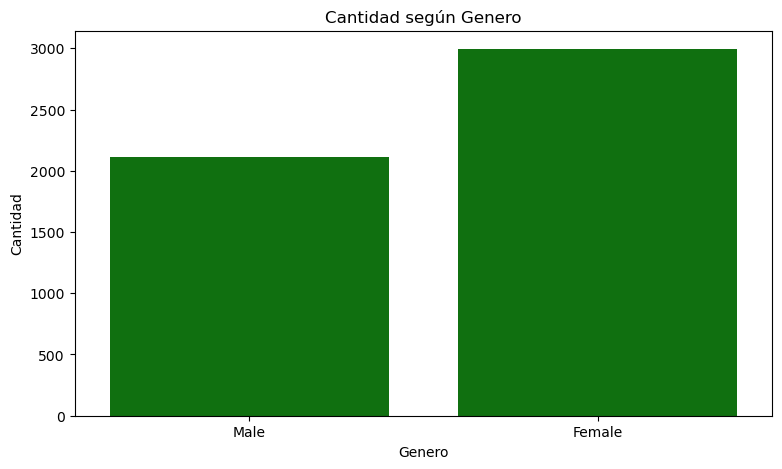

In [32]:
plt.figure(figsize=(9,5))
sns.countplot(data=datosIctus, x='Genero', color='Green')
plt.title("Cantidad según Genero")
plt.xlabel("Genero")
plt.ylabel("Cantidad")
plt.show()

#### Analisis

- Podemos ver que hay mayor cantidad de mujeres que hombres
- Ambos tienen mas de 2000 datos

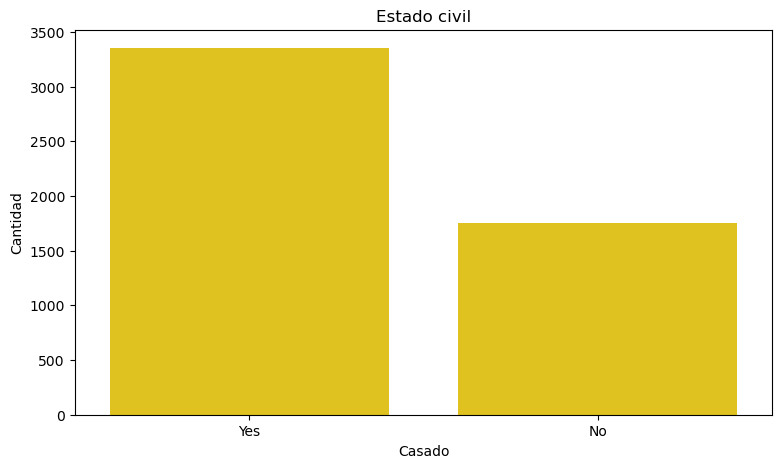

In [33]:
plt.figure(figsize=(9,5))
sns.countplot(data=datosIctus, x='EdoCivil', color='Gold')
plt.title("Estado civil")
plt.xlabel("Casado")
plt.ylabel("Cantidad")
plt.show()

#### Analisis

- Podemos ver que hay mayor cantidad de casados que solteros

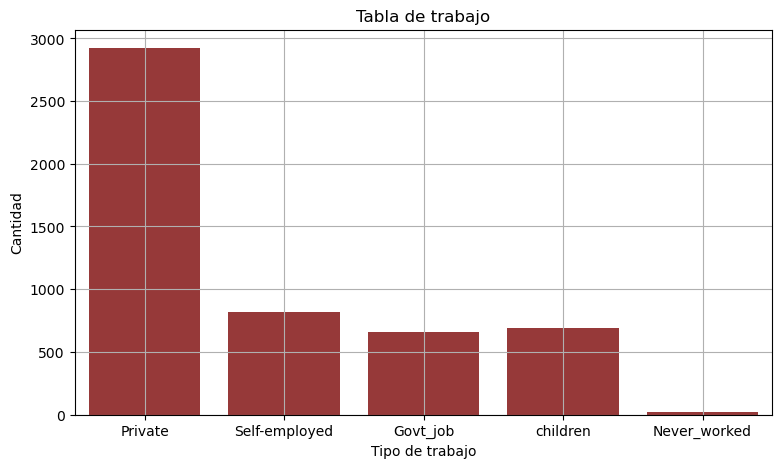

In [34]:
plt.figure(figsize=(9,5))
sns.countplot(data=datosIctus, x='TipoTrabajo', color='Brown')
plt.title("Tabla de trabajo")
plt.xlabel("Tipo de trabajo")
plt.ylabel("Cantidad")
plt.grid()
plt.show()

#### Analisis

- La mayoria de personas tienen un empleo en empresa privada, siendo mas de el doble que la segunda.
- La cantidad de personas que nunca han trabajado es muy baja

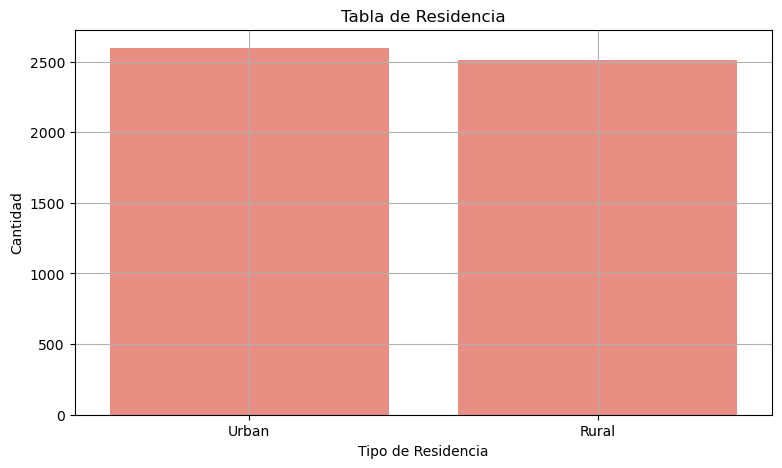

In [35]:
plt.figure(figsize=(9,5))
sns.countplot(data=datosIctus, x='TipoResidencia', color='Salmon')
plt.title("Tabla de Residencia")
plt.xlabel("Tipo de Residencia")
plt.ylabel("Cantidad")
plt.grid()
plt.show()

#### Analisis

- Es muy pareja la cantidad de personas que viven en rural y urbano 
- Ambos tienen mas de 2500

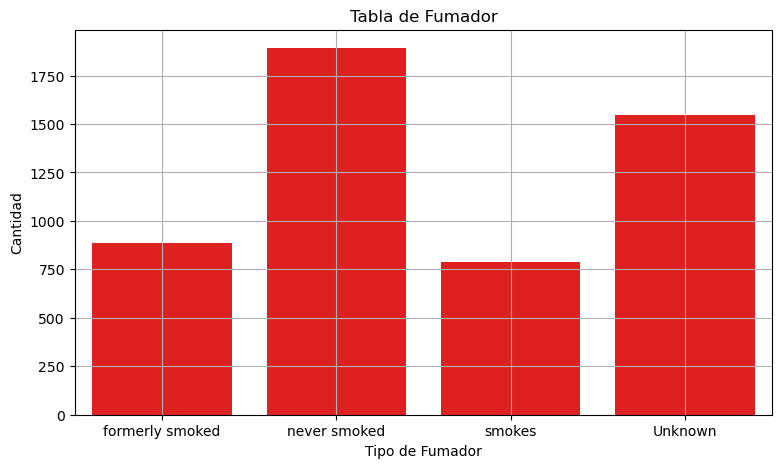

In [36]:
plt.figure(figsize=(9,5))
sns.countplot(data=datosIctus, x='Fumador', color='r')
plt.title("Tabla de Fumador")
plt.xlabel("Tipo de Fumador")
plt.ylabel("Cantidad")
plt.grid()
plt.show()

#### Analisis

- La mayoria de personas nunca ha fumado
- La minoria de personas fuma
- Es interesante como el  dato de personas que no saben si han fumado es el 2 con mas cantidad

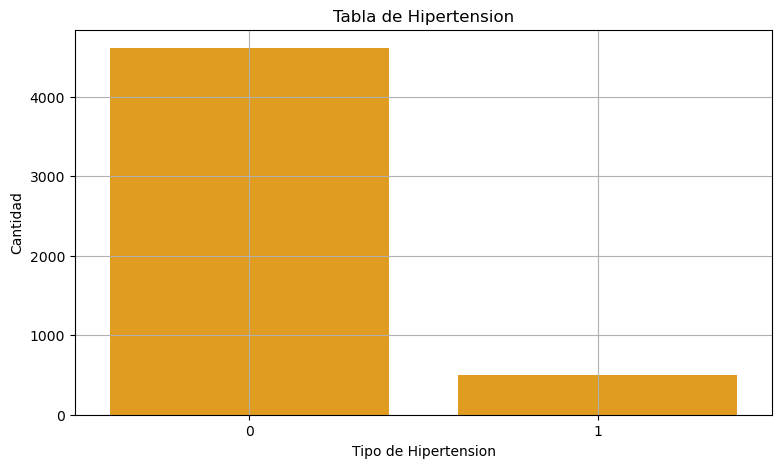

In [37]:
plt.figure(figsize=(9,5))
sns.countplot(data=datosIctus, x='Hipertension', color='orange')
plt.title("Tabla de Hipertension")
plt.xlabel("Tipo de Hipertension")
plt.ylabel("Cantidad")
plt.grid()
plt.show()

#### Analisis

- Por mucha diferencia la mayoria de personas no tienen hipertension 

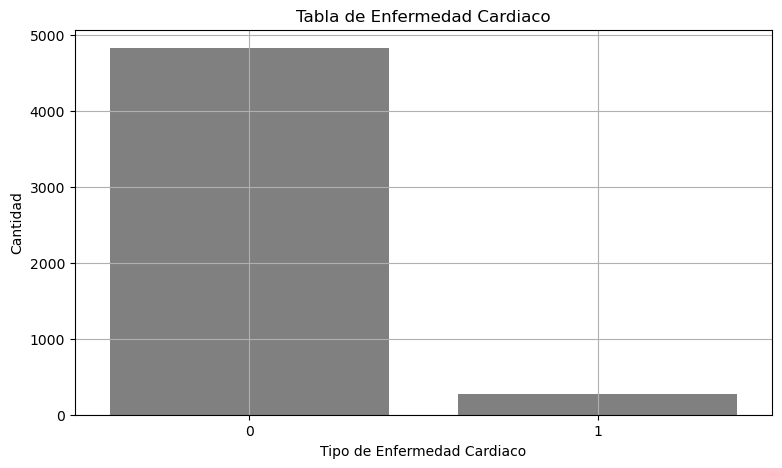

In [38]:
plt.figure(figsize=(9,5))
sns.countplot(data=datosIctus, x='EnfCardiaco', color='grey')
plt.title("Tabla de Enfermedad Cardiaco")
plt.xlabel("Tipo de Enfermedad Cardiaco")
plt.ylabel("Cantidad")
plt.grid()
plt.show()

#### Analisis

- La mayoria de personas no ha tenido enfermedades cardiacas

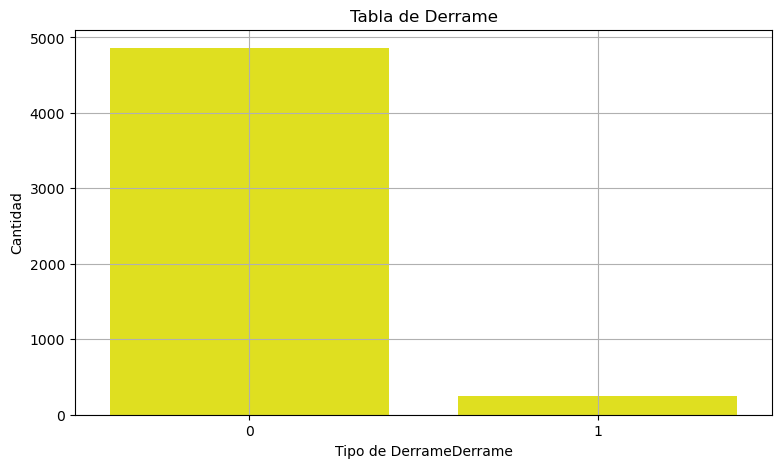

In [39]:
plt.figure(figsize=(9,5))
sns.countplot(data=datosIctus, x='Derrame', color='Yellow')
plt.title("Tabla de Derrame")
plt.xlabel("Tipo de DerrameDerrame")
plt.ylabel("Cantidad")
plt.grid()
plt.show()

#### Analisis

- Podemos ver que es muy baja la cantidad de personas que han tenido derrames

### **Grafica de los datos CUANTITATIVAS**

In [40]:
df03.printSchema()

root
 |-- id: integer (nullable = true)
 |-- Genero: string (nullable = true)
 |-- Edad: integer (nullable = true)
 |-- Hipertension: integer (nullable = true)
 |-- EnfCardiaco: integer (nullable = true)
 |-- EdoCivil: string (nullable = true)
 |-- TipoTrabajo: string (nullable = true)
 |-- TipoResidencia: string (nullable = true)
 |-- NivelGlucosa: double (nullable = true)
 |-- IMC: double (nullable = true)
 |-- Fumador: string (nullable = true)
 |-- Derrame: integer (nullable = true)



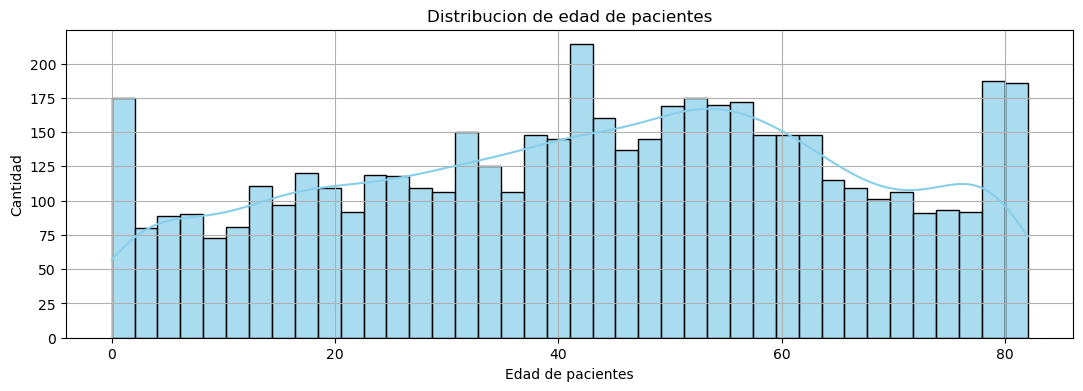

In [41]:
plt.figure(figsize=(13,4))
sns.histplot(data=datosIctus, x='Edad', bins=40, kde=True, color='skyblue', alpha=0.7)
plt.title("Distribucion de edad de pacientes")
plt.xlabel("Edad de pacientes")
plt.ylabel("Cantidad")
plt.grid()
plt.show()

#### Analisis

- La mayor cantidad de pacientes esta entre los 40-60 años

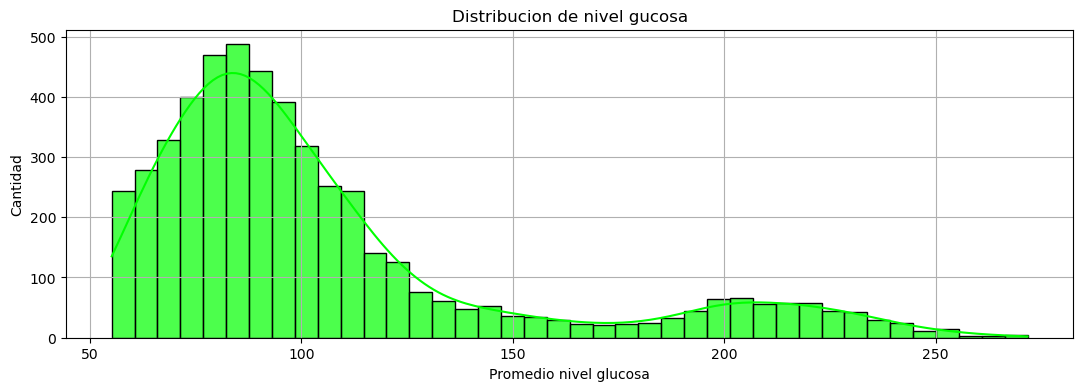

In [42]:
plt.figure(figsize=(13,4))
sns.histplot(data=datosIctus, x='NivelGlucosa', bins=40, kde=True, color='lime', alpha=0.7)
plt.title("Distribucion de nivel gucosa")
plt.xlabel("Promedio nivel glucosa")
plt.ylabel("Cantidad")
plt.grid()
plt.show()

#### Analisis

- El nivel de glucosa tiene una cantidad muy alta del promedio 50 al 100

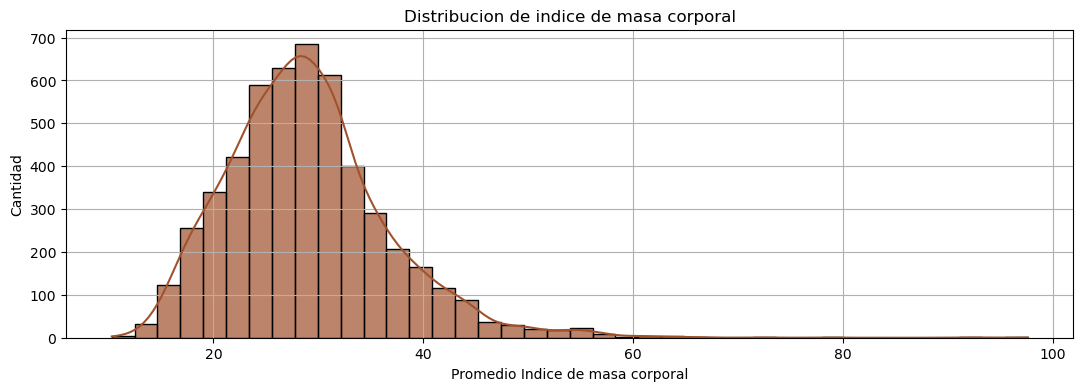

In [43]:
plt.figure(figsize=(13,4))
sns.histplot(data=datosIctus, x='IMC', bins=40, kde=True, color='sienna', alpha=0.7)
plt.title("Distribucion de indice de masa corporal")
plt.xlabel("Promedio Indice de masa corporal")
plt.ylabel("Cantidad")
plt.grid()
plt.show()

#### Analisis

- El promedio de indice de masa corporal con mas cantidad es el 30

### **Combinacion de graficas Cuantitativas y Cualitativas**

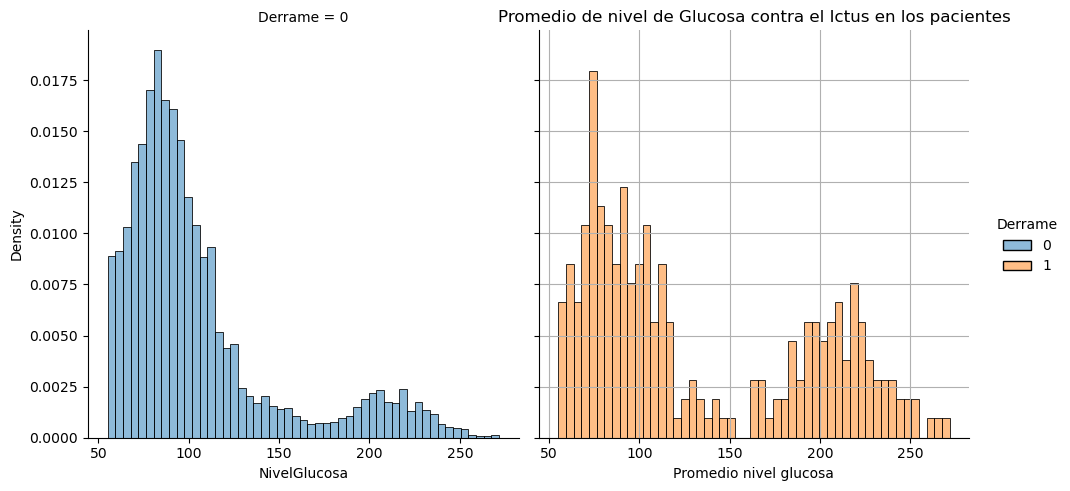

In [44]:
### Se requiere observar el promedio de nivel de Glucosa contra el Ictus en los pacientes
sns.displot(data=datosIctus, x='NivelGlucosa', hue='Derrame', col='Derrame', stat='density', common_norm=False)
plt.title("Promedio de nivel de Glucosa contra el Ictus en los pacientes")
plt.xlabel("Promedio nivel glucosa")
plt.ylabel("Densidad")
plt.grid()
plt.show()

#### Analisis

- Los pacientes que sufrieron un derrame tienen una presencia mucho mayor en los niveles altos de glucosa  en comparación con los pacientes sanos . Esto demuestra que los niveles elevados de azúcar en la sangre están directamente relacionados con un mayor riesgo de sufrir un ictus.

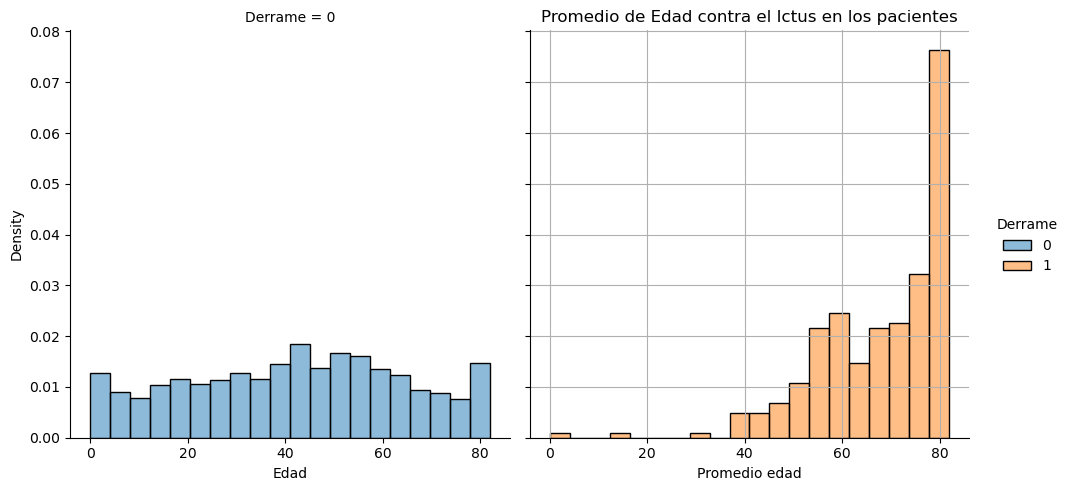

In [45]:
### Se requiere observar el promedio de edad contra el Ictus en los pacientes
sns.displot(data=datosIctus, x='Edad', hue='Derrame', col='Derrame', stat='density', common_norm=False)
plt.title("Promedio de Edad contra el Ictus en los pacientes")
plt.xlabel("Promedio edad")
plt.ylabel("Densidad")
plt.grid()
plt.show()

#### Analisis

- Podemos ver que el promedio de edad con mayor derrames es en pacientes con edad avanzada

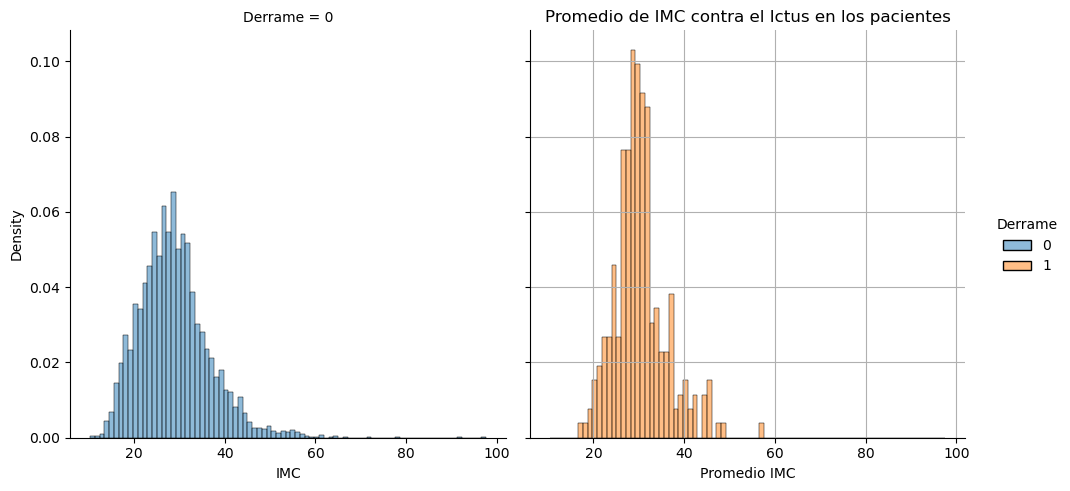

In [46]:
### Se requiere observar el promedio de IMC contra el Ictus en los pacientes
sns.displot(data=datosIctus, x='IMC', hue='Derrame', col='Derrame', stat='density', common_norm=False)
plt.title("Promedio de IMC contra el Ictus en los pacientes")
plt.xlabel("Promedio IMC")
plt.ylabel("Densidad")
plt.grid()
plt.show()

### ANALISIS
- Podemos ver que el derrame es mas alto en los que tienen un promedio de IMC entre 20 y 40 siendo el 30 el mas alto

## Se requiere generar una nueva columna "AltoRiesgo"
- Nivel de Glucosa <126 y edad> = 41
- Caso contrario = 0

In [47]:
df04 = df03.withColumn('AltoRiesgo', F.when ((F.col('Edad')>41)&(F.col('NivelGlucosa')<126),1).otherwise(0))
df04.show(4)

+-----+------+----+------------+-----------+--------+-------------+--------------+------------+-----+---------------+-------+----------+
|   id|Genero|Edad|Hipertension|EnfCardiaco|EdoCivil|  TipoTrabajo|TipoResidencia|NivelGlucosa|  IMC|        Fumador|Derrame|AltoRiesgo|
+-----+------+----+------------+-----------+--------+-------------+--------------+------------+-----+---------------+-------+----------+
| 9046|  Male|  67|           0|          1|     Yes|      Private|         Urban|      228.69| 36.6|formerly smoked|      1|         0|
|51676|Female|  61|           0|          0|     Yes|Self-employed|         Rural|      202.21|30.78|   never smoked|      1|         0|
|31112|  Male|  80|           0|          1|     Yes|      Private|         Rural|      105.92| 32.5|   never smoked|      1|         1|
|60182|Female|  49|           0|          0|     Yes|      Private|         Urban|      171.23| 34.4|         smokes|      1|         0|
+-----+------+----+------------+---------

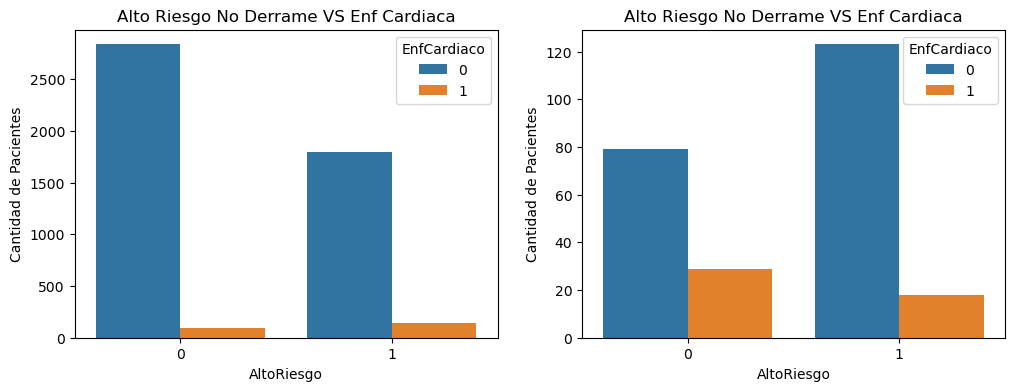

In [48]:
####################
# Graficas de Alto Riesgo Segun Derrame vs Enf Cardiaco
####################
pandasDatos = df04.toPandas()

fig, matrix = plt.subplots(1,2, figsize=(12,4))

matrix[0].set_title("Alto Riesgo No Derrame VS Enf Cardiaca")
matrix[0].set_ylabel("Cantidad de Pacientes")
matrix0 = sns.countplot(data=pandasDatos.loc[pandasDatos['Derrame'] == 0], x = 'AltoRiesgo', hue = 'EnfCardiaco', ax = matrix[0])
matrix[1].set_title("Alto Riesgo No Derrame VS Enf Cardiaca")
matrix[1].set_ylabel("Cantidad de Pacientes")
matrix1 = sns.countplot(data=pandasDatos.loc[pandasDatos['Derrame'] == 1], x = 'AltoRiesgo', hue = 'EnfCardiaco', ax = matrix[1])


### Analisis
- Podemos ver que los pacientes sin enfermedad cardiaca tienen más probabilidad a no tener un derrame.

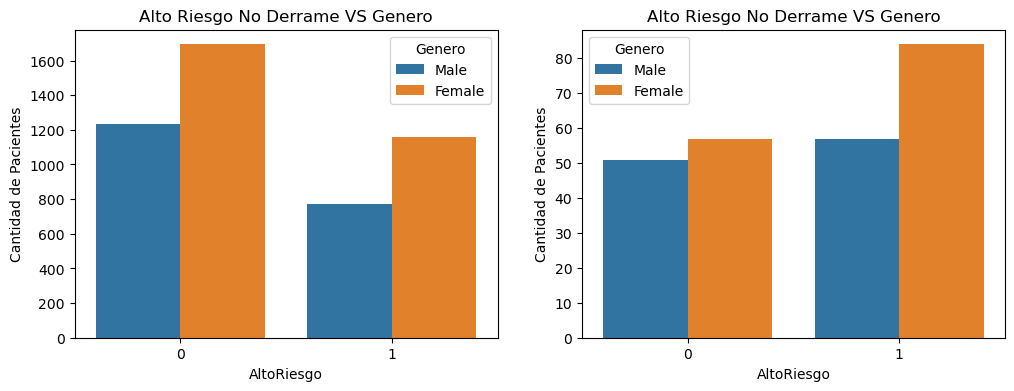

In [49]:
####################
# Graficas de Alto Riesgo Segun Derrame vs genero
####################
pandasDatos = df04.toPandas()

fig, matrix = plt.subplots(1,2, figsize=(12,4))

matrix[0].set_title("Alto Riesgo No Derrame VS Genero")
matrix[0].set_ylabel("Cantidad de Pacientes")
matrix0 = sns.countplot(data=pandasDatos.loc[pandasDatos['Derrame'] == 0], x = 'AltoRiesgo', hue = 'Genero', ax = matrix[0])
matrix[1].set_title("Alto Riesgo No Derrame VS Genero")
matrix[1].set_ylabel("Cantidad de Pacientes")
matrix1 = sns.countplot(data=pandasDatos.loc[pandasDatos['Derrame'] == 1], x = 'AltoRiesgo', hue = 'Genero', ax = matrix[1])


### Analisis
- Se puede ver que que las mujeres tienen mas cantidad de pacientes con riesgo a tener un derrame

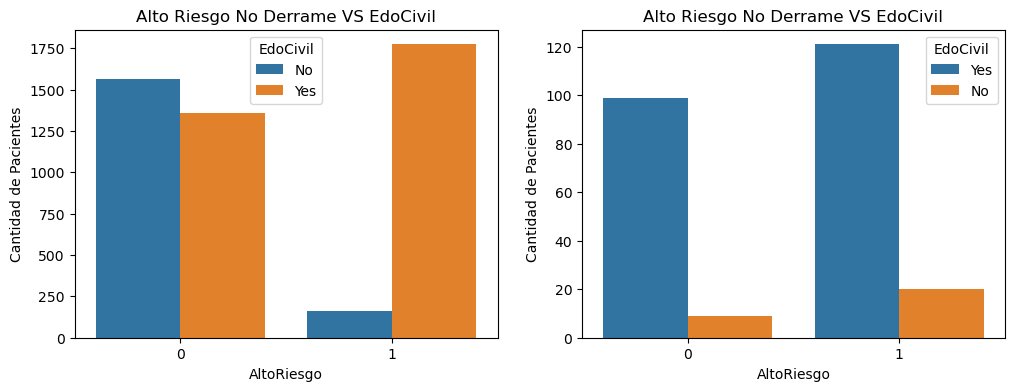

In [50]:
####################
# Graficas de Alto Riesgo Segun Derrame vs Casado
####################
pandasDatos = df04.toPandas()

fig, matrix = plt.subplots(1,2, figsize=(12,4))

matrix[0].set_title("Alto Riesgo No Derrame VS EdoCivil")
matrix[0].set_ylabel("Cantidad de Pacientes")
matrix0 = sns.countplot(data=pandasDatos.loc[pandasDatos['Derrame'] == 0], x = 'AltoRiesgo', hue = 'EdoCivil', ax = matrix[0])
matrix[1].set_title("Alto Riesgo No Derrame VS EdoCivil")
matrix[1].set_ylabel("Cantidad de Pacientes")
matrix1 = sns.countplot(data=pandasDatos.loc[pandasDatos['Derrame'] == 1], x = 'AltoRiesgo', hue = 'EdoCivil', ax = matrix[1])


### Analisis
- Las personas casadas son mas propensas a tener un derrame

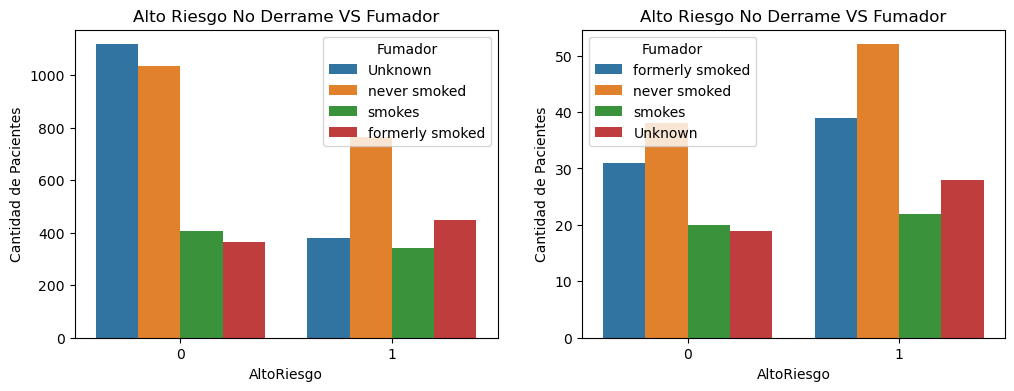

In [51]:
####################
# Graficas de Alto Riesgo Segun Derrame vs Fumador
####################
pandasDatos = df04.toPandas()

fig, matrix = plt.subplots(1,2, figsize=(12,4))

matrix[0].set_title("Alto Riesgo No Derrame VS Fumador")
matrix[0].set_ylabel("Cantidad de Pacientes")
matrix0 = sns.countplot(data=pandasDatos.loc[pandasDatos['Derrame'] == 0], x = 'AltoRiesgo', hue = 'Fumador', ax = matrix[0])
matrix[1].set_title("Alto Riesgo No Derrame VS Fumador")
matrix[1].set_ylabel("Cantidad de Pacientes")
matrix1 = sns.countplot(data=pandasDatos.loc[pandasDatos['Derrame'] == 1], x = 'AltoRiesgo', hue = 'Fumador', ax = matrix[1])


### Analisis
- Las personas con mayor riesdo de derrame en nuestros datos son las que nunca han fumado

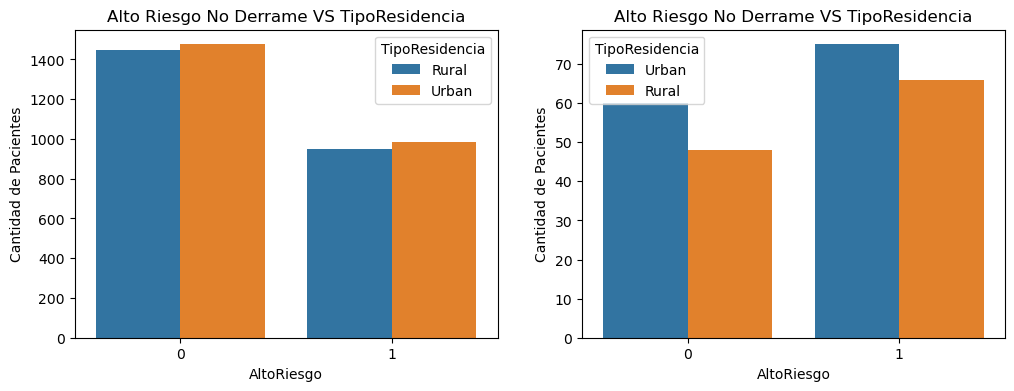

In [52]:
####################
# Graficas de Alto Riesgo Segun Derrame vs TipoResidencia
####################
pandasDatos = df04.toPandas()

fig, matrix = plt.subplots(1,2, figsize=(12,4))

matrix[0].set_title("Alto Riesgo No Derrame VS TipoResidencia")
matrix[0].set_ylabel("Cantidad de Pacientes")
matrix0 = sns.countplot(data=pandasDatos.loc[pandasDatos['Derrame'] == 0], x = 'AltoRiesgo', hue = 'TipoResidencia', ax = matrix[0])
matrix[1].set_title("Alto Riesgo No Derrame VS TipoResidencia")
matrix[1].set_ylabel("Cantidad de Pacientes")
matrix1 = sns.countplot(data=pandasDatos.loc[pandasDatos['Derrame'] == 1], x = 'AltoRiesgo', hue = 'TipoResidencia', ax = matrix[1])


# Analisis
- La mayot cantidad de personas con alto riesgo de derrame viven en residenia urbana

### **Se requiere observar las categorias**
- La idea es cambiar cada categoria a un valor (ejemplo: Rural=0, Urban=1,...etc)

In [53]:
df04.columns

['id',
 'Genero',
 'Edad',
 'Hipertension',
 'EnfCardiaco',
 'EdoCivil',
 'TipoTrabajo',
 'TipoResidencia',
 'NivelGlucosa',
 'IMC',
 'Fumador',
 'Derrame',
 'AltoRiesgo']

In [54]:
#Se revuisa cuales son las categorias
df04.select('Genero').distinct().show()
df04.select('EdoCivil').distinct().show()
df04.select('TipoTrabajo').distinct().show()
df04.select('TipoResidencia').distinct().show()
df04.select('Fumador').distinct().show()

+------+
|Genero|
+------+
|Female|
|  Male|
+------+

+--------+
|EdoCivil|
+--------+
|      No|
|     Yes|
+--------+

+-------------+
|  TipoTrabajo|
+-------------+
| Never_worked|
|Self-employed|
|      Private|
|     children|
|     Govt_job|
+-------------+

+--------------+
|TipoResidencia|
+--------------+
|         Urban|
|         Rural|
+--------------+

+---------------+
|        Fumador|
+---------------+
|         smokes|
|        Unknown|
|   never smoked|
|formerly smoked|
+---------------+



In [55]:
###### Se requiere eliminar la columna ID : No aporta informacion
df05 = df04.drop('id')
## Verificar
df05.columns

['Genero',
 'Edad',
 'Hipertension',
 'EnfCardiaco',
 'EdoCivil',
 'TipoTrabajo',
 'TipoResidencia',
 'NivelGlucosa',
 'IMC',
 'Fumador',
 'Derrame',
 'AltoRiesgo']

### Cambio de variables en Categorias

In [56]:
## Columnas NO catgoricas
noCategoricas=  ['Genero','Hipertension', 'EnfCardiaco','NivelGlucosa','IMC','Derrame','AltoRiesgo']

## Se hace un indice para las columnas (Categoricas y no categoricas)
indice = [StringIndexer(inputCol=columna, outputCol=columna+"_IND").fit(df05)
            for columna in list(set(df05.columns)-set(noCategoricas))
         
         ]

In [57]:
### La idea es ahora generar un tratamiento en SECUENCIA o ETAPAS: PIPELINE
pipeBD = Pipeline(stages=indice)
### Se crea un nuev objeto df para tener secuencia en las versiones
df06 = pipeBD.fit(df05).transform(df05)
df06.show(5)

+------+----+------------+-----------+--------+-------------+--------------+------------+-----+---------------+-------+----------+---------------+-----------+------------+------------------+--------+
|Genero|Edad|Hipertension|EnfCardiaco|EdoCivil|  TipoTrabajo|TipoResidencia|NivelGlucosa|  IMC|        Fumador|Derrame|AltoRiesgo|TipoTrabajo_IND|Fumador_IND|EdoCivil_IND|TipoResidencia_IND|Edad_IND|
+------+----+------------+-----------+--------+-------------+--------------+------------+-----+---------------+-------+----------+---------------+-----------+------------+------------------+--------+
|  Male|  67|           0|          1|     Yes|      Private|         Urban|      228.69| 36.6|formerly smoked|      1|         0|            0.0|        2.0|         0.0|               0.0|    64.0|
|Female|  61|           0|          0|     Yes|Self-employed|         Rural|      202.21|30.78|   never smoked|      1|         0|            1.0|        0.0|         0.0|               1.0|    16.0|


In [58]:
## Se borran columnas categoricas
categoricas = ['Genero','EdoCivil', 'TipoTrabajo','TipoResidencia','Fumador']
df06 = df06.drop(*categoricas)

df06.show(4)

+----+------------+-----------+------------+-----+-------+----------+---------------+-----------+------------+------------------+--------+
|Edad|Hipertension|EnfCardiaco|NivelGlucosa|  IMC|Derrame|AltoRiesgo|TipoTrabajo_IND|Fumador_IND|EdoCivil_IND|TipoResidencia_IND|Edad_IND|
+----+------------+-----------+------------+-----+-------+----------+---------------+-----------+------------+------------------+--------+
|  67|           0|          1|      228.69| 36.6|      1|         0|            0.0|        2.0|         0.0|               0.0|    64.0|
|  61|           0|          0|      202.21|30.78|      1|         0|            1.0|        0.0|         0.0|               1.0|    16.0|
|  80|           0|          1|      105.92| 32.5|      1|         1|            0.0|        0.0|         0.0|               1.0|    29.0|
|  49|           0|          0|      171.23| 34.4|      1|         0|            0.0|        3.0|         0.0|               0.0|    12.0|
+----+------------+--------

#### **Division de Datos en variables Independientes y dependientes**

- Se usara el sistema 80% y 20%
- 80% para entrenamiento de los datos (el modelo sabe las respuestas)
- 20% para prueba (el modelo no conoce respuestas)
- Se calcula el porcentaje de valores positivos de la variable dependiente (Ictus=1)

In [59]:
## Se hace uso del vector ensamblador para el uso de los modelos
varIndependientes = VectorAssembler(inputCols=df06.drop('Derrame').columns,
                                    outputCol='Independientes')
### Se aplica la transformacion
varIndependientes = varIndependientes.transform(df06).select('Independientes','Derrame')

### Se observa el vector
varIndependientes.show(5,False)


+----------------------------------------------------+-------+
|Independientes                                      |Derrame|
+----------------------------------------------------+-------+
|(11,[0,2,3,4,7,10],[67.0,1.0,228.69,36.6,2.0,64.0]) |1      |
|(11,[0,3,4,6,9,10],[61.0,202.21,30.78,1.0,1.0,16.0])|1      |
|[80.0,0.0,1.0,105.92,32.5,1.0,0.0,0.0,0.0,1.0,29.0] |1      |
|(11,[0,3,4,7,10],[49.0,171.23,34.4,3.0,12.0])       |1      |
|[79.0,1.0,0.0,174.12,24.0,0.0,1.0,0.0,0.0,1.0,7.0]  |1      |
+----------------------------------------------------+-------+
only showing top 5 rows



In [60]:
### Division de conjuntos de entrenamiento y prueba
df07 = varIndependientes.select(['Independientes','Derrame'])

### Division por aleatoriedad
entrenamiento, prueba = df07.randomSplit([0.8,0.2])

In [61]:
### Revision de porcentaje en conjunto de entrenamiento (Derrame=1)
totalPacientes = df07.count()
totalPacDrrame = df07.select('Derrame').where("Derrame == 1").count()
totalEntrenamiento=entrenamiento.count()
pacientesEntreDerrame=entrenamiento.select('Derrame').where("Derrame==1").count()

print(f"Total pacientes= {totalPacientes}")
print(f"Total pacientes con Derrame = {totalPacDrrame}")
print(f"Total porcentaje con derrame = {round(totalPacDrrame/totalPacientes,2)}%")
print(f"Pacientes en Entrenamiento = {totalEntrenamiento}")
print(f"Pacientes Entrenamiento Derrame = {pacientesEntreDerrame}")
print(f"Entrenamiento Porcentaje con Derrame = {round(pacientesEntreDerrame/totalEntrenamiento,2)}%")


Total pacientes= 5109
Total pacientes con Derrame = 249
Total porcentaje con derrame = 0.05%
Pacientes en Entrenamiento = 4068
Pacientes Entrenamiento Derrame = 206
Entrenamiento Porcentaje con Derrame = 0.05%


### ***Modelos MLib***
- Logistic Regretion
- Random Forest
- Decision Tree
- Support Vector
- Multilayer Perception Classifier

In [62]:
### Regresion Logistica
from pyspark.ml.classification import LogisticRegression

### Se instala el modelo
RegLog = LogisticRegression(featuresCol='Independientes', labelCol = 'Derrame')

### Se entrena el modelo sobre los datos de entrenamiento
modeloRL = RegLog.fit(entrenamiento)

### Se hacen predicciones sobre datos de prueba
prediccionRL = modeloRL.transform(prueba)

### Se observan las predicciones
prediccionRL.show(5)

+--------------------+-------+--------------------+--------------------+----------+
|      Independientes|Derrame|       rawPrediction|         probability|prediction|
+--------------------+-------+--------------------+--------------------+----------+
|(11,[0,1,2,3,4,9]...|      0|[0.53721490467254...|[0.63116429606741...|       0.0|
|(11,[0,1,2,3,4,10...|      0|[1.74794064654599...|[0.85169286900646...|       0.0|
|(11,[0,1,3,4,5,10...|      0|[3.56960062558269...|[0.97260454975093...|       0.0|
|(11,[0,1,3,4,5,10...|      0|[2.41692608277068...|[0.91810892914020...|       0.0|
|(11,[0,1,3,4,5,10...|      0|[2.22406345839802...|[0.90238970108907...|       0.0|
+--------------------+-------+--------------------+--------------------+----------+
only showing top 5 rows



### Evaluacion ModeloRL

In [63]:
### accuracy : Exactitud
accuracyRL = MulticlassClassificationEvaluator(labelCol='Derrame',
                                               metricName='accuracy').evaluate(prediccionRL)
precisionRL = MulticlassClassificationEvaluator(labelCol='Derrame',
                                                metricName='weightedPrecision').evaluate(prediccionRL)
recallRL = MulticlassClassificationEvaluator(labelCol='Derrame',
                                                metricName='weightedRecall').evaluate(prediccionRL)

# Se imprimen 
print(f"\t Exactitud en modelo RL = \t\t {round(accuracyRL*100,2)} %")
print(f"\t Precision en modelo RL = \t\t {round(precisionRL*100,2)} %")
print(f"\t Exactitud en modelo RL = \t\t {round(recallRL*100,2)} %")

	 Exactitud en modelo RL = 		 95.87 %
	 Precision en modelo RL = 		 91.91 %
	 Exactitud en modelo RL = 		 95.87 %


In [66]:
### No para todos los MODELOS se puede pintar las siguientes graficas
RO_RL = modeloRL.summary.roc.toPandas()
predicRL = modeloRL.summary.pr.toPandas()
y_trueRL = prediccionRL.select('Derrame').toPandas()
y_predRL = prediccionRL.select('prediction').toPandas()
confMatrixRL = confusion_matrix(y_trueRL, y_predRL)

<function matplotlib.pyplot.show(close=None, block=None)>

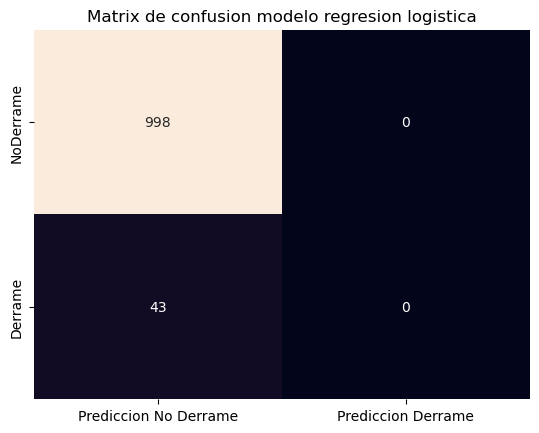

In [67]:
### Graficas modelo RL
plt.title('Matrix de confusion modelo regresion logistica')
sns.heatmap(confMatrixRL, annot=True, fmt='d', cbar=False,
            xticklabels=['Prediccion No Derrame', 'Prediccion Derrame'],
            yticklabels=['NoDerrame', 'Derrame'])

plt.show

### Random Forest

In [73]:
### Random Forest
from pyspark.ml.classification import RandomForestClassifier

### Se instala el modelo
### maxBins se sube a 100 porque Edad_IND tiene 83 categorias (por defecto solo acepta 32)
RanFor = RandomForestClassifier(featuresCol='Independientes', labelCol='Derrame', maxBins=100)

### Se entrena el modelo sobre los datos de entrenamiento
modeloRF = RanFor.fit(entrenamiento)

### Se hacen predicciones sobre datos de prueba
prediccionRF = modeloRF.transform(prueba)

### Se observan las predicciones
prediccionRF.show(5)

+--------------------+-------+--------------------+--------------------+----------+
|      Independientes|Derrame|       rawPrediction|         probability|prediction|
+--------------------+-------+--------------------+--------------------+----------+
|(11,[0,1,2,3,4,9]...|      0|[13.3898954282554...|[0.66949477141277...|       0.0|
|(11,[0,1,2,3,4,10...|      0|[16.5261991725256...|[0.82630995862628...|       0.0|
|(11,[0,1,3,4,5,10...|      0|[18.9741279443954...|[0.94870639721977...|       0.0|
|(11,[0,1,3,4,5,10...|      0|[18.1991757005303...|[0.90995878502651...|       0.0|
|(11,[0,1,3,4,5,10...|      0|[18.0888531014559...|[0.90444265507279...|       0.0|
+--------------------+-------+--------------------+--------------------+----------+
only showing top 5 rows



### Evaluacion ModeloRF

In [74]:
### accuracy : Exactitud
accuracyRF = MulticlassClassificationEvaluator(labelCol='Derrame',
                                               metricName='accuracy').evaluate(prediccionRF)
precisionRF = MulticlassClassificationEvaluator(labelCol='Derrame',
                                                metricName='weightedPrecision').evaluate(prediccionRF)
recallRF = MulticlassClassificationEvaluator(labelCol='Derrame',
                                                metricName='weightedRecall').evaluate(prediccionRF)

# Se imprimen 
print(f"\t Exactitud en modelo RF = \t\t {round(accuracyRF*100,2)} %")
print(f"\t Precision en modelo RF = \t\t {round(precisionRF*100,2)} %")
print(f"\t Recall en modelo RF = \t\t\t {round(recallRF*100,2)} %")

	 Exactitud en modelo RF = 		 95.87 %
	 Precision en modelo RF = 		 91.91 %
	 Recall en modelo RF = 			 95.87 %


In [75]:
### Se sacan los valores reales y las predicciones para la matriz de confusion
y_trueRF = prediccionRF.select('Derrame').toPandas()
y_predRF = prediccionRF.select('prediction').toPandas()
confMatrixRF = confusion_matrix(y_trueRF, y_predRF)

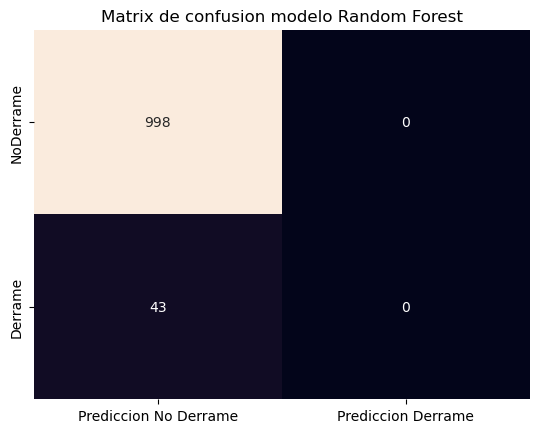

In [76]:
### Graficas modelo RF
plt.title('Matrix de confusion modelo Random Forest')
sns.heatmap(confMatrixRF, annot=True, fmt='d', cbar=False,
            xticklabels=['Prediccion No Derrame', 'Prediccion Derrame'],
            yticklabels=['NoDerrame', 'Derrame'])

plt.show()

### Decision Tree

In [78]:
### Arbol de Decision
from pyspark.ml.classification import DecisionTreeClassifier

### Se instala el modelo
### maxBins se sube a 100 porque Edad_IND tiene 83 categorias (por defecto solo acepta 32)
ArbDec = DecisionTreeClassifier(featuresCol='Independientes', labelCol='Derrame', maxBins=100)

### Se entrena el modelo sobre los datos de entrenamiento
modeloDT = ArbDec.fit(entrenamiento)

### Se hacen predicciones sobre datos de prueba
prediccionDT = modeloDT.transform(prueba)

### Se observan las predicciones
prediccionDT.show(5)

+--------------------+-------+-------------+--------------------+----------+
|      Independientes|Derrame|rawPrediction|         probability|prediction|
+--------------------+-------+-------------+--------------------+----------+
|(11,[0,1,2,3,4,9]...|      0|  [63.0,28.0]|[0.69230769230769...|       0.0|
|(11,[0,1,2,3,4,10...|      0| [460.0,16.0]|[0.96638655462184...|       0.0|
|(11,[0,1,3,4,5,10...|      0|  [555.0,9.0]|[0.98404255319148...|       0.0|
|(11,[0,1,3,4,5,10...|      0| [532.0,86.0]|[0.86084142394822...|       0.0|
|(11,[0,1,3,4,5,10...|      0| [532.0,86.0]|[0.86084142394822...|       0.0|
+--------------------+-------+-------------+--------------------+----------+
only showing top 5 rows



### Evaluacion ModeloDT

In [79]:
### accuracy : Exactitud
accuracyDT = MulticlassClassificationEvaluator(labelCol='Derrame',
                                               metricName='accuracy').evaluate(prediccionDT)
precisionDT = MulticlassClassificationEvaluator(labelCol='Derrame',
                                                metricName='weightedPrecision').evaluate(prediccionDT)
recallDT = MulticlassClassificationEvaluator(labelCol='Derrame',
                                                metricName='weightedRecall').evaluate(prediccionDT)

# Se imprimen 
print(f"\t Exactitud en modelo DT = \t\t {round(accuracyDT*100,2)} %")
print(f"\t Precision en modelo DT = \t\t {round(precisionDT*100,2)} %")
print(f"\t Recall en modelo DT = \t\t\t {round(recallDT*100,2)} %")

	 Exactitud en modelo DT = 		 95.0 %
	 Precision en modelo DT = 		 92.68 %
	 Recall en modelo DT = 			 95.0 %


In [80]:
### El arbol de decision no tiene summary, solo se saca la matriz de confusion
y_trueDT = prediccionDT.select('Derrame').toPandas()
y_predDT = prediccionDT.select('prediction').toPandas()
confMatrixDT = confusion_matrix(y_trueDT, y_predDT)

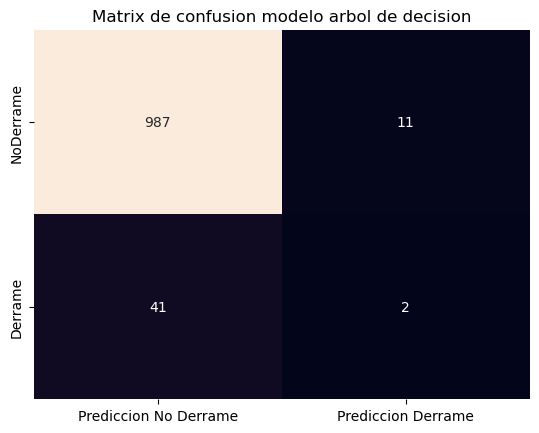

In [81]:
### Graficas modelo DT
plt.title('Matrix de confusion modelo arbol de decision')
sns.heatmap(confMatrixDT, annot=True, fmt='d', cbar=False,
            xticklabels=['Prediccion No Derrame', 'Prediccion Derrame'],
            yticklabels=['NoDerrame', 'Derrame'])

plt.show()

### Support Vector Machine

In [82]:
### Maquina de soporte vectorial (Lineal)
from pyspark.ml.classification import LinearSVC

### Se instala el modelo
SopVec = LinearSVC(featuresCol='Independientes', labelCol='Derrame', maxIter=10)

### Se entrena el modelo sobre los datos de entrenamiento
modeloSVM = SopVec.fit(entrenamiento)

### Se hacen predicciones sobre datos de prueba
prediccionSVM = modeloSVM.transform(prueba)

### Se observan las predicciones
prediccionSVM.show(5)

+--------------------+-------+--------------------+----------+
|      Independientes|Derrame|       rawPrediction|prediction|
+--------------------+-------+--------------------+----------+
|(11,[0,1,2,3,4,9]...|      0|[0.99089296191047...|       0.0|
|(11,[0,1,2,3,4,10...|      0|[1.07959423233312...|       0.0|
|(11,[0,1,3,4,5,10...|      0|[1.20632871464137...|       0.0|
|(11,[0,1,3,4,5,10...|      0|[1.09330661564466...|       0.0|
|(11,[0,1,3,4,5,10...|      0|[1.05039641488579...|       0.0|
+--------------------+-------+--------------------+----------+
only showing top 5 rows



### Evaluacion ModeloSVM

In [83]:
### accuracy : Exactitud
accuracySVM = MulticlassClassificationEvaluator(labelCol='Derrame',
                                               metricName='accuracy').evaluate(prediccionSVM)
precisionSVM = MulticlassClassificationEvaluator(labelCol='Derrame',
                                                metricName='weightedPrecision').evaluate(prediccionSVM)
recallSVM = MulticlassClassificationEvaluator(labelCol='Derrame',
                                                metricName='weightedRecall').evaluate(prediccionSVM)

# Se imprimen 
print(f"\t Exactitud en modelo SVM = \t\t {round(accuracySVM*100,2)} %")
print(f"\t Precision en modelo SVM = \t\t {round(precisionSVM*100,2)} %")
print(f"\t Recall en modelo SVM = \t\t {round(recallSVM*100,2)} %")

	 Exactitud en modelo SVM = 		 95.87 %
	 Precision en modelo SVM = 		 91.91 %
	 Recall en modelo SVM = 		 95.87 %


In [84]:
### Se sacan los valores reales y las predicciones para la matriz de confusion
y_trueSVM = prediccionSVM.select('Derrame').toPandas()
y_predSVM = prediccionSVM.select('prediction').toPandas()
confMatrixSVM = confusion_matrix(y_trueSVM, y_predSVM)

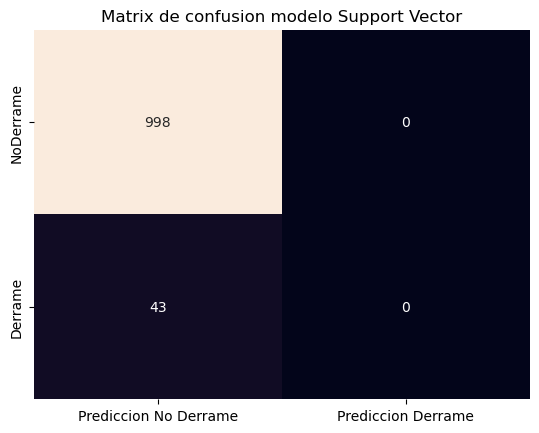

In [85]:
### Graficas modelo SVM
plt.title('Matrix de confusion modelo Support Vector')
sns.heatmap(confMatrixSVM, annot=True, fmt='d', cbar=False,
            xticklabels=['Prediccion No Derrame', 'Prediccion Derrame'],
            yticklabels=['NoDerrame', 'Derrame'])

plt.show()

### Multilayer Perceptron Classifier

In [86]:
### Perceptron Multicapa
from pyspark.ml.classification import MultilayerPerceptronClassifier

### Se calcula cuantas variables independientes entran al modelo (capa de entrada)
numEntradas = len(entrenamiento.first()['Independientes'])

### Capas: entrada, 2 capas ocultas y salida (2 clases: Derrame 0 o 1)
capas = [numEntradas, 8, 4, 2]

### Se instala el modelo
PerMul = MultilayerPerceptronClassifier(featuresCol='Independientes', labelCol='Derrame',
                                        layers=capas, maxIter=100, seed=1234)

### Se entrena el modelo sobre los datos de entrenamiento
modeloMLP = PerMul.fit(entrenamiento)

### Se hacen predicciones sobre datos de prueba
prediccionMLP = modeloMLP.transform(prueba)

### Se observan las predicciones
prediccionMLP.show(5)

+--------------------+-------+--------------------+--------------------+----------+
|      Independientes|Derrame|       rawPrediction|         probability|prediction|
+--------------------+-------+--------------------+--------------------+----------+
|(11,[0,1,2,3,4,9]...|      0|[0.16013382340773...|[0.87075802765426...|       0.0|
|(11,[0,1,2,3,4,10...|      0|[0.16013422060339...|[0.87075811148008...|       0.0|
|(11,[0,1,3,4,5,10...|      0|[0.90928202917146...|[0.96499327762270...|       0.0|
|(11,[0,1,3,4,5,10...|      0|[0.34847372666376...|[0.90484323374944...|       0.0|
|(11,[0,1,3,4,5,10...|      0|[0.91030517844907...|[0.96505847588044...|       0.0|
+--------------------+-------+--------------------+--------------------+----------+
only showing top 5 rows



### Evaluacion ModeloMLP

In [87]:
### accuracy : Exactitud
accuracyMLP = MulticlassClassificationEvaluator(labelCol='Derrame',
                                               metricName='accuracy').evaluate(prediccionMLP)
precisionMLP = MulticlassClassificationEvaluator(labelCol='Derrame',
                                                metricName='weightedPrecision').evaluate(prediccionMLP)
recallMLP = MulticlassClassificationEvaluator(labelCol='Derrame',
                                                metricName='weightedRecall').evaluate(prediccionMLP)

# Se imprimen 
print(f"\t Exactitud en modelo MLP = \t\t {round(accuracyMLP*100,2)} %")
print(f"\t Precision en modelo MLP = \t\t {round(precisionMLP*100,2)} %")
print(f"\t Recall en modelo MLP = \t\t {round(recallMLP*100,2)} %")

	 Exactitud en modelo MLP = 		 95.87 %
	 Precision en modelo MLP = 		 91.91 %
	 Recall en modelo MLP = 		 95.87 %


In [88]:
### Se sacan los valores reales y las predicciones para la matriz de confusion
y_trueMLP = prediccionMLP.select('Derrame').toPandas()
y_predMLP = prediccionMLP.select('prediction').toPandas()
confMatrixMLP = confusion_matrix(y_trueMLP, y_predMLP)

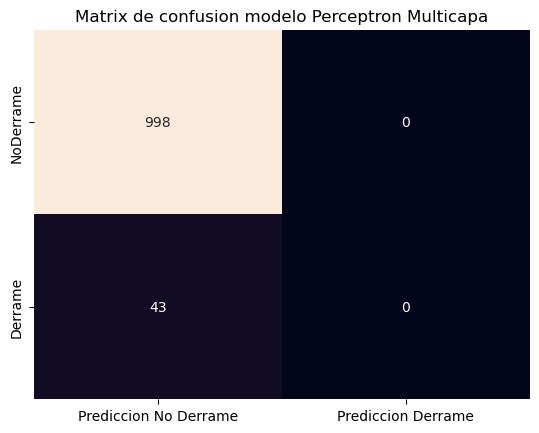

In [89]:
### Graficas modelo MLP
plt.title('Matrix de confusion modelo Perceptron Multicapa')
sns.heatmap(confMatrixMLP, annot=True, fmt='d', cbar=False,
            xticklabels=['Prediccion No Derrame', 'Prediccion Derrame'],
            yticklabels=['NoDerrame', 'Derrame'])

plt.show()

### Comparacion de modelos

In [90]:
### Se crea una tabla para comparar los resultados de todos los modelos
comparacion = pd.DataFrame({
    'Modelo': ['Regresion Logistica', 'Random Forest', 'Decision Tree', 'Support Vector', 'Perceptron Multicapa'],
    'Exactitud': [accuracyRL, accuracyRF, accuracyDT, accuracySVM, accuracyMLP],
    'Precision': [precisionRL, precisionRF, precisionDT, precisionSVM, precisionMLP],
    'Recall': [recallRL, recallRF, recallDT, recallSVM, recallMLP]
})
comparacion[['Exactitud','Precision','Recall']] = (comparacion[['Exactitud','Precision','Recall']]*100).round(2)
comparacion

,Modelo,Exactitud,Precision,Recall
0,Regresion Logistica,95.87,91.91,95.87
1,Random Forest,95.87,91.91,95.87
2,Decision Tree,95.00,92.68,95.00
3,Support Vector,95.87,91.91,95.87
4,Perceptron Multicapa,95.87,91.91,95.87


## **CONCLUSIONES**

### Sobre los datos
- El dataset tiene 5109 pacientes y solo 249 tuvieron derrame, es decir cerca del 5%
- Esto hace que los datos esten muy desbalanceados, hay muchisimos mas pacientes sin derrame que con derrame
- Las variables que mas se relacionan con el derrame son la Edad, el Nivel de Glucosa, la Hipertension y la Enfermedad Cardiaca
- Los pacientes de edad avanzada y con niveles altos de glucosa son los que mas presentan derrames
- La variable IMC tenia 201 datos nulos (4%) y se reemplazaron por el promedio segun genero y rango de edad para no perder informacion

### Sobre los modelos
| Modelo | Exactitud | Precision | Recall |
|---|---|---|---|
| Regresion Logistica | 95.87 % | 91.91 % | 95.87 % |
| Random Forest | 95.87 % | 91.91 % | 95.87 % |
| Decision Tree | 95.00 % | 92.68 % | 95.00 % |
| Support Vector | 95.87 % | 91.91 % | 95.87 % |
| Perceptron Multicapa | 95.87 % | 91.91 % | 95.87 % |

- Cuatro de los cinco modelos dieron exactamente el mismo resultado (95.87%)
- Ese 95.87% es justamente el porcentaje de pacientes SIN derrame en el conjunto de prueba
- Esto significa que esos modelos aprendieron a decir siempre "No Derrame", y asi aciertan casi siempre, pero no detectan a los pacientes que si tienen derrame
- En las matrices de confusion se puede ver que la columna de "Prediccion Derrame" queda en 0 o casi en 0
- El Decision Tree tiene un poco menos de exactitud (95%) pero tiene la precision mas alta (92.68%), porque es el unico que se arriesga a predecir algunos casos de derrame
- Por eso el Decision Tree seria el modelo mas util de los cinco, aunque todavia detecta muy pocos casos

### Conclusion general
- En datos de salud la exactitud no es suficiente para decir que un modelo es bueno, porque cuando los datos estan desbalanceados un modelo puede tener una exactitud alta sin servir para detectar la enfermedad
- En este caso es mas grave no detectar a un paciente con derrame (falso negativo) que equivocarse con uno sano
- Se cumplio con la metodologia CRISP-DM: entendimiento de los datos, preparacion, modelado y evaluacion

In [91]:
sparkClavijo.stop()